# Body States Detection — v2

Predicts four things from a full-body photo: **age group, height group, weight group and gender**, trained on the
[Celeb-FBI](https://www.kaggle.com/datasets/pronaydebnath1/celeb-fbi) dataset.

### What changed from v1

| v1 problem | v2 fix |
|---|---|
| The Kaggle API key was printed into the saved notebook | Credentials come from Colab Secrets and are never printed |
| LDA was fitted on **all** images before the train/test split, so the 91–98 % "after LDA" scores were inflated | Every step sits inside a scikit-learn `Pipeline` that only ever sees training images (section 8 shows the difference) |
| Accuracy only, no baseline: v1's 80 % for age is exactly what always guessing "adult" scores | Compared against "always guess the biggest group"; balanced accuracy, macro-F1, confusion matrices, cross-validation |
| Unknown values are written as `0` (984 weights, 443 heights); v1 turned them into "underweight" and "short" | `0` means unknown; each target is trained on the photos where its value is known |
| Weights like `54.5w` were dropped; height `5.10` (5 ft 10 in) was read as 5.1 ft, so 1,272 people of 5 ft 10–11 counted as "average" | One parser for the file names, feet.inches → cm, decimal weights kept, impossible values (`8.5h`, `5.3w`, `2023a`) reported and ignored |
| Weight group ignored height | Weight group from BMI (WHO cut-offs) |
| Full-body photos squashed into 150×150 squares | Aspect ratio kept (gray padding) |
| Same photo/person could be in both train and test | Duplicates and likely-same-person images are kept on one side |
| 8 models retrained for every uploaded photo, photo used as-is | Models trained once and saved; the person in your photo is detected and cropped first |

### Two tracks, compared on the same split
- **Classical:** HOG features → PCA → (LDA) → SVM or logistic regression
- **Deep:** features from a pretrained CNN (ResNet-50, ImageNet) → SVM or logistic regression

### Before you run
1. **Runtime → Change runtime type → T4 GPU** (CPU works, the CNN step is just slower).
2. Add your Kaggle credentials as Colab Secrets (section 1).
3. **Runtime → Run all.** The first run takes roughly 20–30 minutes; features are cached, so re-runs are faster.

## 0. Setup
Imports, settings and a fixed random seed so results are repeatable. Every setting lives in this cell.
If you change one, re-run the notebook from here.

In [6]:
import hashlib, json, os, random, re, shutil, subprocess, sys, time, warnings, zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torchvision
from joblib import Parallel, delayed, dump, load
from skimage.feature import hog
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             classification_report, f1_score, mean_absolute_error)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from torchvision import models

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable, **kwargs):
        return iterable

IN_COLAB = 'google.colab' in sys.modules
QUICK = os.environ.get('BSD_QUICK') == '1'      # tiny search grids, only for a fast smoke test

# ---- Paths ----
DATA_DIR = Path(os.environ.get('CELEB_FBI_DIR', '/content/celeb-fbi'))   # the dataset is unzipped here
WORK_DIR = Path(os.environ.get('BSD_WORK_DIR', '/content/bsd_work'))     # cached features and saved models
KAGGLE_DATASET = 'pronaydebnath1/celeb-fbi'

# ---- Images and features ----
HOG_SIZE = (128, 256)            # (width, height), roughly a standing person; images are padded, never stretched
HOG_PARAMS = dict(orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), block_norm='L2-Hys')
CNN_BACKBONE = 'resnet50'        # or 'convnext_tiny'
CNN_SIZE = 224
BATCH_SIZE = 64
PCA_COMPONENTS = 20 if QUICK else 150

# ---- Groups (shares on Celeb-FBI in brackets; check section 3 and adjust if you like) ----
AGE_BINS, AGE_LABELS = [0, 30, 45, np.inf], ['young', 'adult', 'old']                  # years   [7 / 59 / 34 %]
HEIGHT_BINS, HEIGHT_LABELS = [0, 163, 173, np.inf], ['short', 'average', 'tall']        # cm      [17 / 35 / 49 %]
BMI_BINS, BMI_LABELS = [0, 18.5, 25, np.inf], ['underweight', 'normal', 'overweight']   # WHO     [15 / 74 / 11 %]
# Plausible values; anything outside is treated as unknown (e.g. 8.5h, 5.3w, 2023a in this dataset)
VALID_RANGES = dict(age=(10, 100), height_cm=(120, 225), weight_kg=(30, 250), bmi=(13, 50))

TARGETS = ['age', 'height', 'weight', 'gender']
TARGET_COLS = {'age': 'age_group', 'height': 'height_group', 'weight': 'weight_group', 'gender': 'gender'}
CLASS_ORDER = {'age': AGE_LABELS, 'height': HEIGHT_LABELS, 'weight': BMI_LABELS, 'gender': ['female', 'male']}

# ---- Evaluation ----
SEED = 42
TEST_FOLDS = 5                   # hold out 1 of 5 folds = 20 % test set
CV_FOLDS = 2 if QUICK else 3
N_JOBS = -1
NUM_WORKERS = 0 if os.name == 'nt' else 2      # image-loading workers for the CNN

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
WORK_DIR.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', category=ConvergenceWarning)

print(f'Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | '
      f'scikit-learn {sklearn.__version__} | opencv {cv2.__version__} | torch {torch.__version__} | device: {DEVICE}')
if DEVICE == 'cpu':
    print('No GPU found: the CNN step (section 6) will take several minutes. '
          'Runtime > Change runtime type > T4 GPU makes it about a minute.')

Python 3.13.16 | numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1 | opencv 4.14.0 | torch 2.11.0+cu130 | device: cuda


**Helper functions.** Training and prediction on your own photo both use these, so both see images exactly the
same way.

In [7]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], np.float32)


def letterbox(img, size, pad_value=114):
    # Fit the image inside size=(width, height) keeping its aspect ratio, then pad the rest with gray.
    w, h = size
    ih, iw = img.shape[:2]
    scale = min(w / iw, h / ih)
    nw, nh = max(1, round(iw * scale)), max(1, round(ih * scale))
    img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR)
    top, left = (h - nh) // 2, (w - nw) // 2
    value = (pad_value,) * 3 if img.ndim == 3 else pad_value
    return cv2.copyMakeBorder(img, top, h - nh - top, left, w - nw - left, cv2.BORDER_CONSTANT, value=value)


def hog_features(img_gray, size=None, params=None):
    return hog(letterbox(img_gray, size or HOG_SIZE), **(params or HOG_PARAMS)).astype(np.float32)


def hog_from_path(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return None if img is None else hog_features(img)


def cnn_input(img_bgr, size=None):
    size = size or CNN_SIZE
    rgb = cv2.cvtColor(letterbox(img_bgr, (size, size)), cv2.COLOR_BGR2RGB)
    x = (rgb.astype(np.float32) / 255 - IMAGENET_MEAN) / IMAGENET_STD
    return torch.from_numpy(x.transpose(2, 0, 1).copy())


class ImageFiles(torch.utils.data.Dataset):
    def __init__(self, paths):
        self.paths = list(paths)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        return cnn_input(cv2.imread(self.paths[i], cv2.IMREAD_COLOR))


def load_backbone(name=None):
    # Pretrained ImageNet network with its last (classification) layer removed: one feature vector per image.
    name = name or CNN_BACKBONE
    if name == 'resnet50':
        net = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        net.fc = torch.nn.Identity()
    elif name == 'convnext_tiny':
        net = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
        net.classifier[2] = torch.nn.Identity()
    else:
        raise ValueError(f'Unknown backbone: {name}')
    return net.eval().to(DEVICE)


@torch.no_grad()
def embed(net, batches):
    return np.concatenate([net(x.to(DEVICE)).float().cpu().numpy() for x in batches])


def load_detector():
    weights = models.detection.FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT
    return models.detection.fasterrcnn_mobilenet_v3_large_fpn(weights=weights).eval().to(DEVICE)


@torch.no_grad()
def crop_person(img_bgr, detector, min_score=0.6, margin=0.05):
    # Crop the largest detected person (COCO label 1) plus a small margin. Returns (crop, box) or (image, None).
    x = torch.from_numpy(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float().div(255)
    out = detector([x.to(DEVICE)])[0]
    keep = (out['labels'] == 1) & (out['scores'] >= min_score)
    if not keep.any():
        return img_bgr, None
    boxes = out['boxes'][keep].cpu().numpy()
    x1, y1, x2, y2 = boxes[((boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])).argmax()]
    mx, my = margin * (x2 - x1), margin * (y2 - y1)
    h, w = img_bgr.shape[:2]
    box = (int(max(0, x1 - mx)), int(max(0, y1 - my)), int(min(w, x2 + mx)), int(min(h, y2 + my)))
    return img_bgr[box[1]:box[3], box[0]:box[2]], box


def cache_path(name, paths, *settings):
    key = hashlib.md5(json.dumps([list(paths), settings], default=str).encode()).hexdigest()[:12]
    return WORK_DIR / f'{name}_{key}.npy'

## 1. Kaggle credentials and download

v1 ran `files.upload()` as the last line of a cell, so Colab printed the uploaded `kaggle.json`, **including the API
key**, into the saved notebook. Treat that key as public: on Kaggle go to **Settings → API → Create New Token** to
replace it.

The safe way to give this notebook your credentials:
1. Click the **🔑 Secrets** icon in Colab's left sidebar.
2. Add `KAGGLE_USERNAME` and `KAGGLE_KEY` (the two values inside `kaggle.json`).
3. Switch on **Notebook access** for both.

If the secrets aren't there, the cell asks you to upload `kaggle.json` instead (any file name works) and never prints it.
The download is skipped when the images are already in `DATA_DIR`.

In [8]:
def find_images(root):
    exts = {'.jpg', '.jpeg', '.png'}
    return sorted(p for p in Path(root).rglob('*') if p.suffix.lower() in exts and '__MACOSX' not in p.parts)


def set_kaggle_credentials():
    if os.environ.get('KAGGLE_USERNAME') and os.environ.get('KAGGLE_KEY'):
        return 'environment variables'
    if (Path.home() / '.kaggle' / 'kaggle.json').exists():
        return '~/.kaggle/kaggle.json'
    if not IN_COLAB:
        raise RuntimeError(f'No Kaggle credentials: set KAGGLE_USERNAME and KAGGLE_KEY, or put the images in {DATA_DIR}')
    from google.colab import userdata
    try:
        os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
        os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
        return 'Colab Secrets'
    except Exception as e:  # secret missing, or notebook access not switched on
        print(f'Colab Secrets not available ({type(e).__name__}). Upload kaggle.json instead:')
    from google.colab import files
    uploaded = files.upload()                  # any file name works, e.g. "kaggle (1).json"
    name, content = next(iter(uploaded.items()))
    creds = json.loads(content)
    os.environ['KAGGLE_USERNAME'], os.environ['KAGGLE_KEY'] = creds['username'], creds['key']
    os.remove(name)                            # don't leave the key lying around in /content
    return 'uploaded kaggle.json (not printed)'


if not find_images(DATA_DIR):
    print('Kaggle credentials from:', set_kaggle_credentials())
    subprocess.run(['kaggle', 'datasets', 'download', '-d', KAGGLE_DATASET, '-p', str(DATA_DIR.parent)], check=True)
    with zipfile.ZipFile(DATA_DIR.parent / f'{KAGGLE_DATASET.split("/")[1]}.zip') as z:
        z.extractall(DATA_DIR)

image_paths = find_images(DATA_DIR)
print(f'{len(image_paths)} image files under {DATA_DIR}')

7211 image files under /content/celeb-fbi


## 2. Read the labels from the file names

File names look like `1021_5.5h_51w_female_26a.png`: id, height, weight, gender, age. One regular expression reads
all of them. Stray spaces (`6.1 0`), trailing underscores (`44a_`), decimal weights (`54.5`) and `.jpeg` files are
handled, and every name it can't read is listed instead of silently skipped.

In [9]:
NAME_RE = re.compile(
    r'^(?P<id>\d+)_(?P<height>[\d.\s]+?)h_(?P<weight>[\d.\s]+?)w_(?P<gender>[a-z]+)_(?P<age>\d+)a$', re.IGNORECASE)
GENDER_FIX = {'femlale': 'female', 'femal': 'female', 'f': 'female', 'm': 'male'}


def parse_name(path):
    m = NAME_RE.match(path.stem.strip().rstrip('_'))
    if not m:
        return None
    try:
        height = re.sub(r'\s+', '', m['height'])        # "6.1 0" -> "6.10"
        feet, _, inches = height.partition('.')
        gender = m['gender'].lower()
        return dict(path=str(path), file=path.name, height_raw=height, feet=int(feet), inches=int(inches or 0),
                    weight_kg=float(re.sub(r'\s+', '', m['weight'])),
                    gender=GENDER_FIX.get(gender, gender), age=int(m['age']))
    except ValueError:
        return None


rows, unreadable = [], []
for p in image_paths:
    r = parse_name(p)
    if r:
        rows.append(r)
    else:
        unreadable.append(p.name)
df = pd.DataFrame(rows)
print(f'Labels read: {len(df)}   File names that could not be read: {len(unreadable)}')
for name in unreadable[:20]:
    print('   ', name)

Labels read: 7208   File names that could not be read: 3
    279_5.11h_54w_female_a.png
    3201_5.5h_59w__53a.png
    3208_5.5h_48w__34a.png


**Height and missing values.** The dataset's data card says heights are feet.inches: `5.5h` is 5 ft 5 in, so `5.10`
(5 ft 10 in) is *taller* than `5.9`. v1 read them as decimal feet, so 5.10 became 5.1. Some names use 12 inches:
`4.12` is 4 ft 12 in = 5 ft 0 in, and the conversion handles that.

**`0` means unknown.** 443 photos have height `0h` and 984 have weight `0w`. v1 binned those zeros as "short" and
"underweight". Here they are marked unknown, and the photo is still used for the targets whose labels are known.

In [10]:
print('How often each inch value appears:')
print(df['inches'].value_counts().sort_index().to_string())
known_height = (df['feet'] > 0) & (df['inches'] <= 12)
df['height_cm'] = (df['feet'] * 30.48 + df['inches'] * 2.54).where(known_height)
df['weight_kg'] = df['weight_kg'].where(df['weight_kg'] > 0)
print(f'\nHeight written as 0 (unknown): {(df["feet"] == 0).sum()}    Weight written as 0 (unknown): {df["weight_kg"].isna().sum()}')

How often each inch value appears:
inches
0     851
1     369
2     481
3     464
4     491
5     609
6     569
7     714
8     578
9     734
10    792
11    480
12     76

Height written as 0 (unknown): 443    Weight written as 0 (unknown): 984


**Sanity checks and groups.** Impossible values (heights like `8.5h`, weights like `5.3w`, ages like `2023a`) are
listed and treated as unknown, again only for that one value. The weight group comes from **BMI** (weight relative to
height), because 70 kg means something different at 155 cm than at 190 cm. A BMI outside 13–50 almost always means a
typo in the weight (some look like pounds), so that weight is treated as unknown too.

In [11]:
def drop_implausible(col, lo, hi):
    bad = df[col].notna() & ~df[col].between(lo, hi)
    if bad.any():
        print(f'{col}: {bad.sum()} implausible value(s) treated as unknown, e.g. {df.loc[bad, "file"].head(4).tolist()}')
    df[col] = df[col].where(~bad)


for col in ['age', 'height_cm', 'weight_kg']:
    drop_implausible(col, *VALID_RANGES[col])
df['bmi'] = df['weight_kg'] / (df['height_cm'] / 100) ** 2
drop_implausible('bmi', *VALID_RANGES['bmi'])
df['weight_kg'] = df['weight_kg'].where(df['bmi'].notna() | df['height_cm'].isna())
df['gender'] = df['gender'].where(df['gender'].isin(['female', 'male']))


def to_group(values, bins, labels):
    return pd.cut(values, bins, labels=labels, right=False).astype(object)   # unknown stays NaN


df['age_group'] = to_group(df['age'], AGE_BINS, AGE_LABELS)
df['height_group'] = to_group(df['height_cm'], HEIGHT_BINS, HEIGHT_LABELS)
df['weight_group'] = to_group(df['bmi'], BMI_BINS, BMI_LABELS)
print('\nPhotos with a known label:')
for t in TARGETS:
    n = df[TARGET_COLS[t]].notna().sum()
    print(f'  {t:7s} {n:5d} of {len(df)}')
df.head()

age: 8 implausible value(s) treated as unknown, e.g. ['2150_5.11h_70w_male_127a.png', '2181_5.5h_52w_female_101a.jpg', '2615_5.7h_104w_male_103a.png', '2658_8.11h_199w_male_105a.png']
height_cm: 5 implausible value(s) treated as unknown, e.g. ['2658_8.11h_199w_male_105a.png', '5839_8.3h_0w_male_37a.png', '6332_2.6h_8w_female_30a.jpg', '7473_7.11h_137w_Male_41a.png']
weight_kg: 2 implausible value(s) treated as unknown, e.g. ['2728_5.7h_5.3w_female_62a.png', '6332_2.6h_8w_female_30a.jpg']
bmi: 8 implausible value(s) treated as unknown, e.g. ['142_5.5h_181w_female_44a.png', '1487_5.3h_132w_female_43a.png', '1724_5.3h_31w_female_30a.png', '2338_5.3h_129w_male_49a.png']

Photos with a known label:
  age      7200 of 7208
  height   6760 of 7208
  weight   6211 of 7208
  gender   7208 of 7208


,path,file,height_raw,feet,inches,weight_kg,gender,age,height_cm,bmi,age_group,height_group,weight_group
0,/content/celeb-fbi/Celeb-FBI Dataset/1000_5.7h...,1000_5.7h_70w_male_46a.jpg,5.7,5,7,70.0,male,46.0,170.18,24.170242,old,average,normal
1,/content/celeb-fbi/Celeb-FBI Dataset/1001_6h_8...,1001_6h_83w_male_68a.png,6,6,0,83.0,male,68.0,182.88,24.816793,old,tall,normal
2,/content/celeb-fbi/Celeb-FBI Dataset/1002_5.2h...,1002_5.2h_50w_female_51a.png,5.2,5,2,50.0,female,51.0,157.48,20.161331,old,short,normal
3,/content/celeb-fbi/Celeb-FBI Dataset/1003_5.10...,1003_5.10h_74w_male_41a.png,5.10,5,10,74.0,male,41.0,177.80,23.408210,adult,tall,normal
4,/content/celeb-fbi/Celeb-FBI Dataset/1004_5.10...,1004_5.10h_67w_female_63a.png,5.10,5,10,67.0,female,63.0,177.80,21.193920,old,tall,normal


## 3. Look at the data

Top row: the raw values with the group boundaries as red lines. Bottom row: how many images fall into each group.

**The "always guess the biggest group" score printed below is the number every model has to beat.** v1 never checked
it: with v1's groups, 80 % of the photos were "adult" and 78 % "normal" weight, so its 80 % (age) and 77 % (weight)
accuracies meant the models had learned nothing.

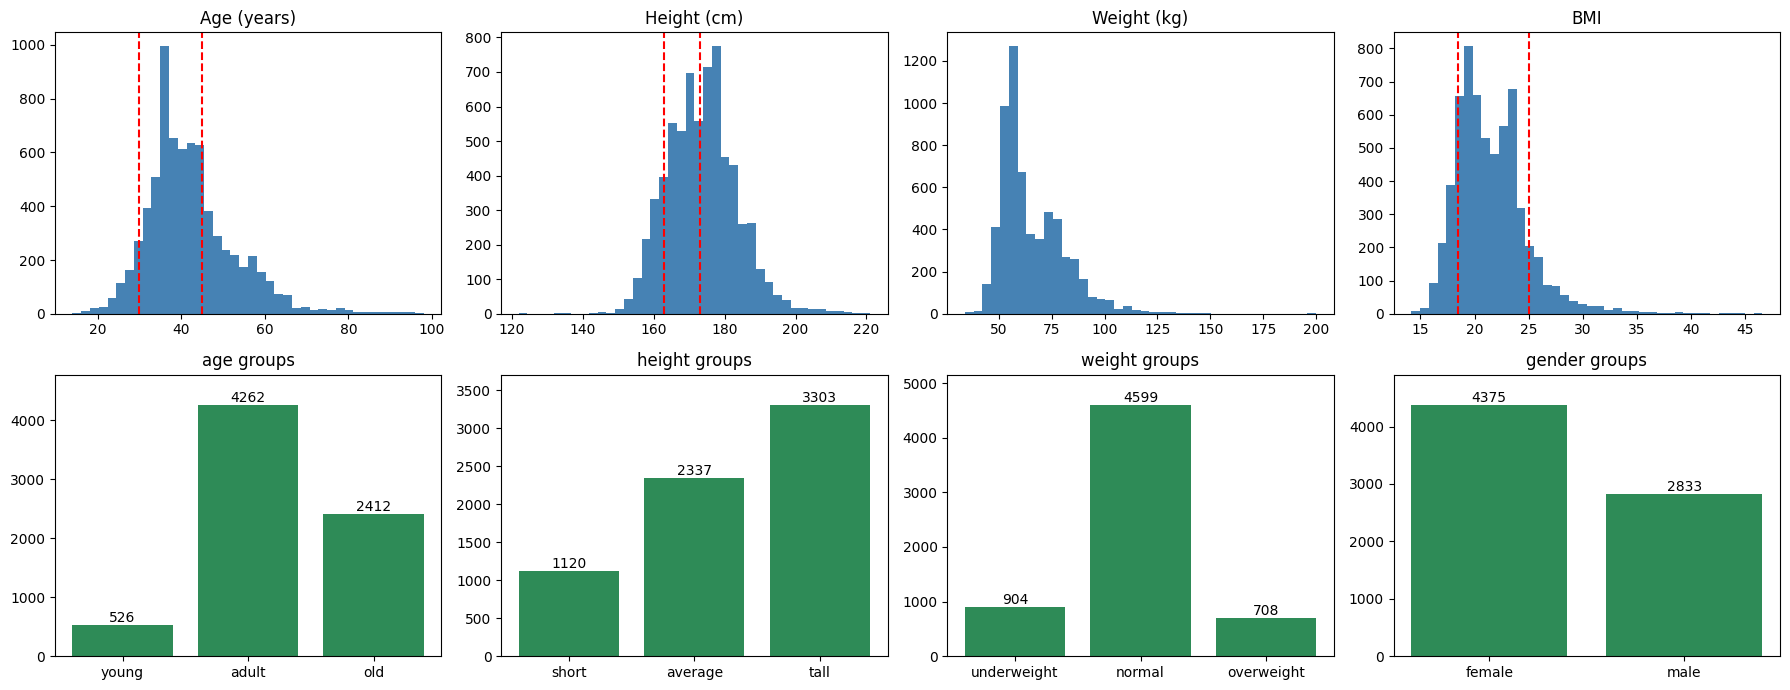

age     biggest group "adult" = 59.2% of the photos with a known age -> always guessing it already scores 59.2% accuracy
height  biggest group "tall" = 48.9% of the photos with a known height -> always guessing it already scores 48.9% accuracy
weight  biggest group "normal" = 74.0% of the photos with a known weight -> always guessing it already scores 74.0% accuracy
gender  biggest group "female" = 60.7% of the photos with a known gender -> always guessing it already scores 60.7% accuracy


In [12]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
raw = [('age', AGE_BINS, 'Age (years)'), ('height_cm', HEIGHT_BINS, 'Height (cm)'),
       ('weight_kg', None, 'Weight (kg)'), ('bmi', BMI_BINS, 'BMI')]
for ax, (col, bins, title) in zip(axes[0], raw):
    ax.hist(df[col].dropna(), bins=40, color='steelblue')
    for b in (bins or [])[1:-1]:
        ax.axvline(b, color='red', ls='--')
    ax.set_title(title)
for ax, t in zip(axes[1], TARGETS):
    counts = df[TARGET_COLS[t]].value_counts().reindex(CLASS_ORDER[t], fill_value=0)
    ax.bar(counts.index, counts.values, color='seagreen')
    for i, v in enumerate(counts.values):
        ax.text(i, v, str(v), ha='center', va='bottom')
    ax.set_ylim(0, counts.max() * 1.12)
    ax.set_title(f'{t} groups')
plt.tight_layout()
plt.show()

for t in TARGETS:
    share = df[TARGET_COLS[t]].value_counts(normalize=True)
    print(f'{t:7s} biggest group "{share.index[0]}" = {share.iloc[0]:.1%} of the photos with a known {t} '
          f'-> always guessing it already scores {share.iloc[0]:.1%} accuracy')

## 4. Keep the same person out of both train and test

If the same photo, or another photo of the same person, is in both the training and the test set, the test score is
too optimistic. File names don't name the person, so two signals are used:
- **identical file contents** (same MD5 hash), and
- **identical labels**: same height, weight, gender and age (only when all four are known). In Celeb-FBI about a third
  of the photos share their exact labels with another photo. That may be the same celebrity, or a coincidence; keeping
  them together is the cautious choice and costs nothing.

Images that share either one form a group, and a group is never split between train and test.

In [13]:
df['md5'] = [hashlib.md5(Path(p).read_bytes()).hexdigest() for p in tqdm(df['path'], desc='hashing')]
complete = df[['height_cm', 'weight_kg', 'age', 'gender']].notna().all(axis=1)
person_key = (df['height_raw'] + '|' + df['weight_kg'].astype(str) + '|' + df['gender'].astype(str) + '|'
              + df['age'].astype(str)).where(complete)

parent = list(range(len(df)))       # union-find: images linked by a shared hash or label set end up in one group


def root(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i


for key in (df['md5'], person_key):
    first = {}
    for i, k in enumerate(key):
        if pd.isna(k):
            continue
        if k in first:
            parent[root(i)] = root(first[k])
        else:
            first[k] = i
df['group'] = [root(i) for i in range(len(df))]

sizes = df['group'].value_counts()
print(f'Exact duplicate files: {len(df) - df["md5"].nunique()}')
print(f'{len(sizes)} groups for {len(df)} images. {int((sizes > 1).sum())} groups hold more than one image '
      f'({int(sizes[sizes > 1].sum())} images). Largest group: {sizes.iloc[0]} images.')

hashing:   0%|          | 0/7208 [00:00<?, ?it/s]

Exact duplicate files: 1
5661 groups for 7208 images. 1031 groups hold more than one image (2578 images). Largest group: 11 images.


## 5. Classical features: HOG

HOG (Histogram of Oriented Gradients) describes the shapes and edges in a grayscale image. Each photo is padded to
128×256 instead of being squashed into a square, so body proportions survive. Features are cached in `WORK_DIR`.

HOG:   0%|          | 0/7208 [00:00<?, ?it/s]

HOG features: (7208, 3780)


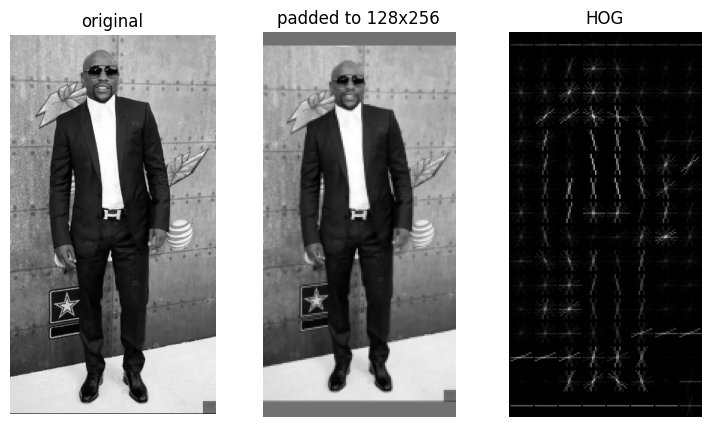

In [14]:
hog_file = cache_path('hog', df['path'], HOG_SIZE, HOG_PARAMS)
if hog_file.exists():
    X_hog = np.load(hog_file)
else:
    feats = Parallel(n_jobs=N_JOBS, batch_size=64)(delayed(hog_from_path)(p) for p in tqdm(df['path'], desc='HOG'))
    dim = next(f.size for f in feats if f is not None)
    X_hog = np.stack([np.full(dim, np.nan, np.float32) if f is None else f for f in feats])
    np.save(hog_file, X_hog)

readable = ~np.isnan(X_hog).any(axis=1)
if not readable.all():
    print('Could not open these images (dropped):', df.loc[~readable, 'file'].tolist())
df, X_hog = df.loc[readable].reset_index(drop=True), X_hog[readable]
print('HOG features:', X_hog.shape)

sample = cv2.imread(df['path'][0], cv2.IMREAD_GRAYSCALE)
_, hog_image = hog(letterbox(sample, HOG_SIZE), visualize=True, **HOG_PARAMS)
fig, axes = plt.subplots(1, 3, figsize=(9, 5))
for ax, img, title in zip(axes, [sample, letterbox(sample, HOG_SIZE), hog_image],
                          ['original', f'padded to {HOG_SIZE[0]}x{HOG_SIZE[1]}', 'HOG']):
    ax.imshow(img, cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.show()

## 6. Deep features: pretrained CNN

A ResNet-50 trained on ImageNet turns each photo into 2,048 numbers that describe what's in it. The network isn't
retrained; only a small classifier is trained on top (section 9). Photos are padded to 224×224, not center-cropped,
which would cut off the head and feet. About a minute on a T4 GPU, several minutes on CPU. Cached afterwards.

In [15]:
cnn_file = cache_path('cnn', df['path'], CNN_BACKBONE, CNN_SIZE)
if cnn_file.exists():
    X_cnn = np.load(cnn_file)
else:
    backbone = load_backbone()
    loader = torch.utils.data.DataLoader(ImageFiles(df['path']), batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
    t0 = time.time()
    X_cnn = embed(backbone, tqdm(loader, desc=f'{CNN_BACKBONE} features'))
    np.save(cnn_file, X_cnn)
    print(f'Done in {time.time() - t0:.0f}s')
print('CNN features:', X_cnn.shape)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:04<00:00, 22.8MB/s]


resnet50 features:   0%|          | 0/113 [00:00<?, ?it/s]

Done in 61s
CNN features: (7208, 2048)


## 7. One train/test split for everything

20 % of the images are held out as the **test set** and not used until section 10. The split keeps the groups from
section 4 together and keeps the label mix similar on both sides. All four targets and both tracks use this same
split, so their scores can be compared directly. For each target, only the photos where that label is known are used
(`split_for` below).

In [16]:
strata = df[[TARGET_COLS[t] for t in TARGETS]].fillna('?').astype(str).agg('|'.join, axis=1)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', UserWarning)    # some label combinations are rare; that's fine here
    train_idx, test_idx = next(StratifiedGroupKFold(TEST_FOLDS, shuffle=True, random_state=SEED)
                               .split(df, strata, groups=df['group']))
assert set(df['group'][train_idx]).isdisjoint(df['group'][test_idx])
print(f'Train: {len(train_idx)} images   Test: {len(test_idx)} images ({len(test_idx) / len(df):.0%})')


def split_for(col):
    # Labels plus train/test positions, keeping only the photos where this label is known.
    y = df[col].to_numpy()
    known = df[col].notna().to_numpy()
    return y, train_idx[known[train_idx]], test_idx[known[test_idx]]


mix = pd.DataFrame({part: {f'{t}: {c}': df.loc[idx, TARGET_COLS[t]].value_counts(normalize=True).get(c, 0)
                           for t in TARGETS for c in CLASS_ORDER[t]}
                    for part, idx in [('train', train_idx), ('test', test_idx)]})
display(mix.style.format('{:.1%}'))

Train: 5778 images   Test: 1430 images (20%)


,train,test
age: young,7.2%,7.7%
age: adult,58.7%,61.3%
age: old,34.1%,31.0%
height: short,16.3%,17.7%
height: average,34.8%,33.8%
height: tall,48.9%,48.6%
weight: underweight,14.5%,14.8%
weight: normal,74.3%,72.8%
weight: overweight,11.2%,12.4%
gender: female,60.3%,62.4%


## 8. Why v1's 95–98 % "after LDA" wasn't real

LDA is **supervised**: it uses the labels to find the directions that best separate the groups. v1 fitted it on all
images, including the test images, and split afterwards, so the test labels had already shaped the features the
model was tested on. Below, the same model (scaler → LDA → SVM on HOG) is scored both ways on the same test set.
Takes a few minutes.

age     v1 way  89.1%    correct way  44.4%
height  v1 way  90.0%    correct way  41.2%
weight  v1 way  96.5%    correct way  50.0%
gender  v1 way  96.9%    correct way  72.0%


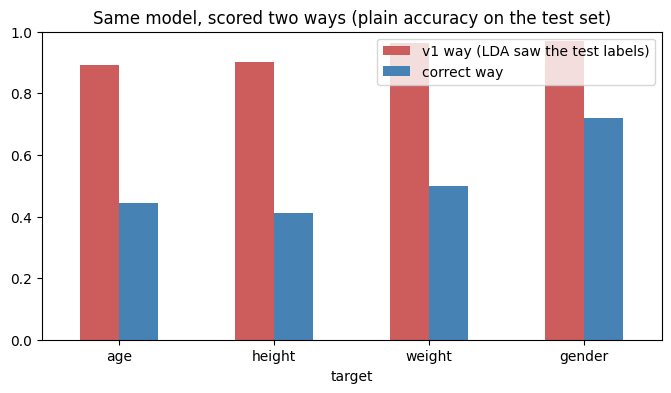

In [17]:
leak_rows = []
for t in TARGETS:
    y, tr, te = split_for(TARGET_COLS[t])
    # v1: scaler and LDA fitted on ALL images (test labels included), split afterwards
    used = np.concatenate([tr, te])
    Z = LDA().fit_transform(StandardScaler().fit_transform(X_hog[used]), y[used])
    v1_way = SVC().fit(Z[:len(tr)], y[tr]).score(Z[len(tr):], y[te])
    # correct: the same steps, fitted on the training images only
    pipe = Pipeline([('scale', StandardScaler()), ('lda', LDA()), ('svm', SVC())])
    correct = pipe.fit(X_hog[tr], y[tr]).score(X_hog[te], y[te])
    leak_rows.append({'target': t, 'v1 way (LDA saw the test labels)': v1_way, 'correct way': correct})
    print(f'{t:7s} v1 way {v1_way:6.1%}    correct way {correct:6.1%}')

pd.DataFrame(leak_rows).set_index('target').plot.bar(
    figsize=(8, 4), ylim=(0, 1), rot=0, color=['indianred', 'steelblue'],
    title='Same model, scored two ways (plain accuracy on the test set)')
plt.show()

## 9. Train and compare models

Each model is tuned with grouped cross-validation **on the training set only**. Models are ranked by **balanced
accuracy**: the average hit rate across the groups, so always guessing the biggest group scores only 1 ÷ (number of
groups), e.g. 33 % for three groups. Can take 15–30 minutes on the full dataset.

| Model | Track | Idea |
|---|---|---|
| Baseline | — | Always predicts the biggest group |
| HOG + PCA + SVM | classical | v1's model, done correctly (PCA keeps it fast) |
| HOG + PCA + LDA + SVM | classical | v1's LDA idea, done correctly; comparing with the row above shows what LDA really adds |
| HOG + PCA + LogReg | classical | Simple linear model |
| CNN + SVM | deep | Pretrained features + SVM |
| CNN + LogReg | deep | Pretrained features + linear model |

In [18]:
def scaled(*steps):
    return Pipeline([('scale', StandardScaler()), *steps])


MODELS = {  # name: (track, features, pipeline, search grid)
    'Baseline (most frequent)': ('baseline', 'hog', Pipeline([('clf', DummyClassifier(strategy='most_frequent'))]), {}),
    'HOG + PCA + SVM': ('classical', 'hog', scaled(('pca', PCA(PCA_COMPONENTS, random_state=SEED)),
                                                   ('clf', SVC(class_weight='balanced'))),
                        {'clf__C': [1, 10]}),
    'HOG + PCA + LDA + SVM': ('classical', 'hog', scaled(('pca', PCA(PCA_COMPONENTS, random_state=SEED)), ('lda', LDA()),
                                                         ('clf', SVC(class_weight='balanced'))),
                              {'clf__C': [0.1, 1, 10]}),
    'HOG + PCA + LogReg': ('classical', 'hog', scaled(('pca', PCA(PCA_COMPONENTS, random_state=SEED)),
                                                      ('clf', LogisticRegression(max_iter=3000, class_weight='balanced'))),
                           {'clf__C': [0.01, 0.1, 1]}),
    'CNN + SVM': ('deep', 'cnn', scaled(('clf', SVC(class_weight='balanced'))),
                  {'clf__C': [1, 10]}),
    'CNN + LogReg': ('deep', 'cnn', scaled(('clf', LogisticRegression(max_iter=3000, class_weight='balanced'))),
                     {'clf__C': [0.001, 0.01, 0.1]}),
}
if QUICK:
    MODELS = {k: (track, feat, pipe, {p: v[:1] for p, v in grid.items()})
              for k, (track, feat, pipe, grid) in MODELS.items()}
FEATURES = {'hog': X_hog, 'cnn': X_cnn}

cv = StratifiedGroupKFold(CV_FOLDS, shuffle=True, random_state=SEED)
results, fitted = [], {}
for t in TARGETS:
    y, tr, _ = split_for(TARGET_COLS[t])
    for name, (track, feat, pipe, grid) in MODELS.items():
        t0 = time.time()
        search = GridSearchCV(pipe, grid, scoring='balanced_accuracy', cv=cv, n_jobs=N_JOBS, error_score='raise')
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', UserWarning)
            search.fit(FEATURES[feat][tr], y[tr], groups=df['group'].to_numpy()[tr])
        fitted[t, name] = search.best_estimator_
        std = search.cv_results_['std_test_score'][search.best_index_]
        results.append(dict(target=t, model=name, track=track, cv_balanced_acc=search.best_score_, cv_std=std,
                            best_params=search.best_params_, seconds=round(time.time() - t0)))
        print(f'{t:7s} {name:26s} {search.best_score_:6.1%} ± {std:4.1%}  {search.best_params_}  '
              f'({results[-1]["seconds"]}s)')
res = pd.DataFrame(results)

age     Baseline (most frequent)    33.3% ± 0.0%  {}  (3s)
age     HOG + PCA + SVM             39.8% ± 0.5%  {'clf__C': 1}  (46s)
age     HOG + PCA + LDA + SVM       40.0% ± 1.6%  {'clf__C': 1}  (26s)
age     HOG + PCA + LogReg          39.4% ± 1.0%  {'clf__C': 0.01}  (21s)
age     CNN + SVM                   41.3% ± 0.7%  {'clf__C': 1}  (293s)
age     CNN + LogReg                42.5% ± 0.9%  {'clf__C': 0.001}  (25s)
height  Baseline (most frequent)    33.3% ± 0.0%  {}  (1s)
height  HOG + PCA + SVM             46.4% ± 1.3%  {'clf__C': 1}  (35s)
height  HOG + PCA + LDA + SVM       44.9% ± 1.3%  {'clf__C': 0.1}  (24s)
height  HOG + PCA + LogReg          45.3% ± 1.3%  {'clf__C': 1}  (16s)
height  CNN + SVM                   49.7% ± 1.3%  {'clf__C': 1}  (234s)
height  CNN + LogReg                50.1% ± 0.7%  {'clf__C': 0.001}  (21s)
weight  Baseline (most frequent)    33.3% ± 0.0%  {}  (1s)
weight  HOG + PCA + SVM             47.6% ± 1.3%  {'clf__C': 1}  (30s)
weight  HOG + PCA + LDA + S

target,age,height,weight,gender
model,,,,
Baseline (most frequent),33.3%,33.3%,33.3%,50.0%
HOG + PCA + SVM,39.8%,46.4%,47.6%,84.5%
HOG + PCA + LDA + SVM,40.0%,44.9%,49.2%,79.4%
HOG + PCA + LogReg,39.4%,45.3%,49.7%,79.3%
CNN + SVM,41.3%,49.7%,51.1%,93.7%
CNN + LogReg,42.5%,50.1%,56.4%,94.0%


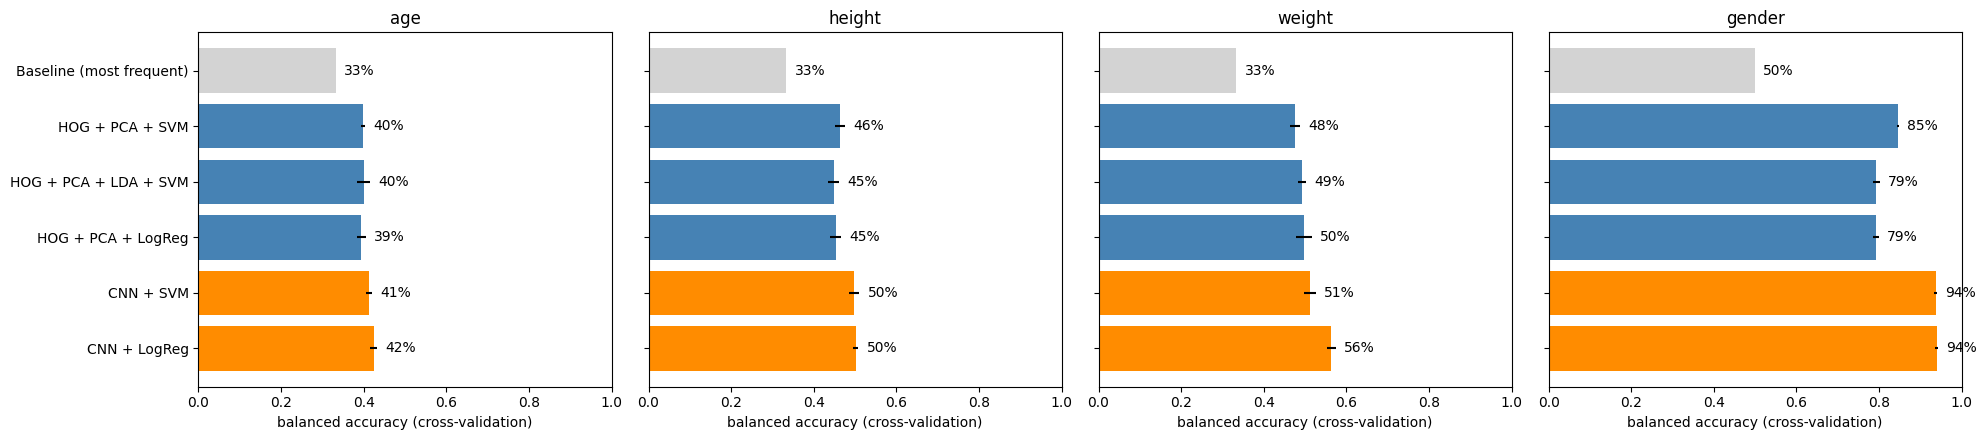

In [19]:
table = res.pivot(index='model', columns='target', values='cv_balanced_acc').reindex(index=list(MODELS), columns=TARGETS)
display(table.style.format('{:.1%}').highlight_max(axis=0, color='#c6efce'))

colors = {'baseline': 'lightgray', 'classical': 'steelblue', 'deep': 'darkorange'}
fig, axes = plt.subplots(1, len(TARGETS), figsize=(20, 4.5), sharey=True)
for ax, t in zip(axes, TARGETS):
    r = res[res['target'] == t]
    ax.barh(r['model'], r['cv_balanced_acc'], xerr=r['cv_std'], color=[colors[k] for k in r['track']])
    for y, (v, s) in enumerate(zip(r['cv_balanced_acc'], r['cv_std'])):
        ax.text(v + s + 0.02, y, f'{v:.0%}', va='center')
    ax.set_xlim(0, 1)
    ax.set_title(t)
    ax.set_xlabel('balanced accuracy (cross-validation)')
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

## 10. Final scores on the test set

For each target, the best classical and the best deep model (chosen by cross-validation in section 9) are now scored
once on the 20 % test set nobody has touched. **Accuracy** is comparable to v1's numbers; **balanced accuracy** and
**macro-F1** show whether the small groups are recognised too.

In [20]:
def best_model(t, track):
    r = res[(res['target'] == t) & (res['track'] == track)]
    return r.loc[r['cv_balanced_acc'].idxmax(), 'model']


test_rows, test_preds = [], {}
for t in TARGETS:
    y, _, te = split_for(TARGET_COLS[t])
    y_test = y[te]
    for track in ['baseline', 'classical', 'deep']:
        name = best_model(t, track)
        pred = fitted[t, name].predict(FEATURES[MODELS[name][1]][te])
        test_preds[t, track] = pred
        test_rows.append(dict(target=t, track=track, model=name, accuracy=accuracy_score(y_test, pred),
                              balanced_accuracy=balanced_accuracy_score(y_test, pred),
                              macro_f1=f1_score(y_test, pred, average='macro', zero_division=0)))
test_res = pd.DataFrame(test_rows)
display(test_res.set_index(['target', 'track']).style.format('{:.1%}', subset=['accuracy', 'balanced_accuracy', 'macro_f1']))

**Confusion matrices.** Each row is the true group and shows where its images went (rows add up to 100 %). A strong
diagonal is good; a full column means the model mostly guesses that one group.

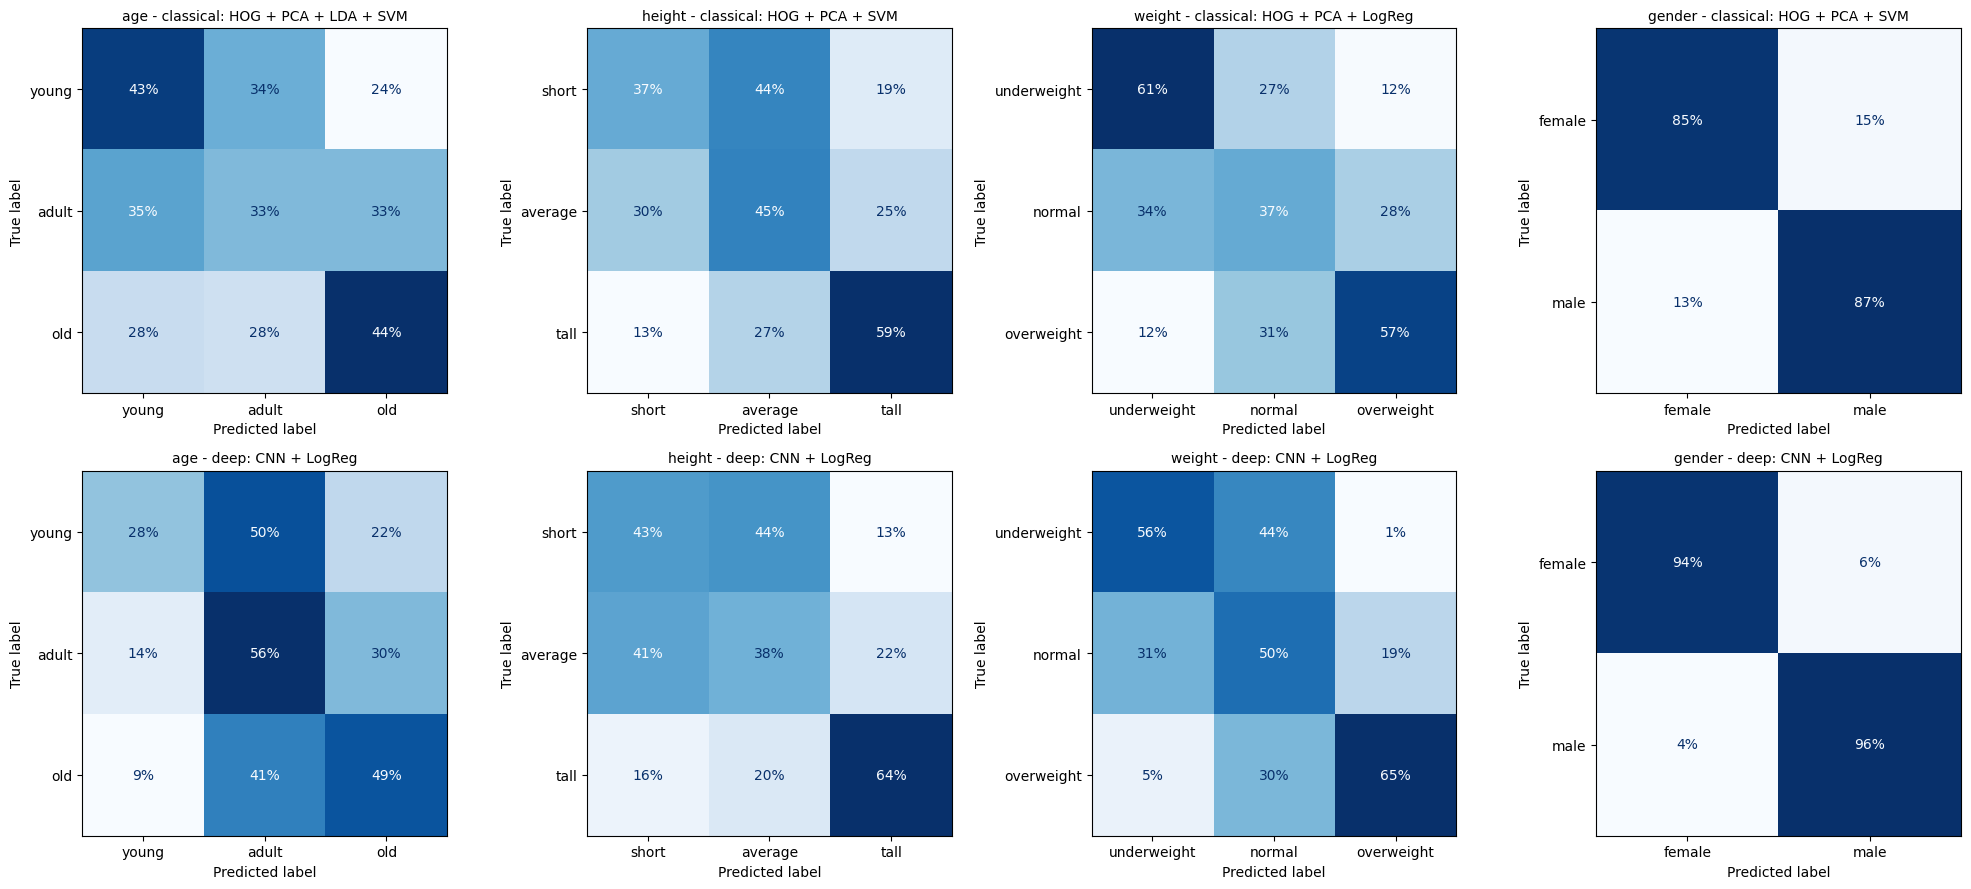

===== age: CNN + LogReg =====
              precision    recall  f1-score   support

       young       0.16      0.28      0.20       110
       adult       0.67      0.56      0.61       876
         old       0.43      0.49      0.46       443

    accuracy                           0.52      1429
   macro avg       0.42      0.44      0.42      1429
weighted avg       0.56      0.52      0.53      1429

===== height: CNN + LogReg =====
              precision    recall  f1-score   support

       short       0.26      0.43      0.32       236
     average       0.42      0.38      0.40       451
        tall       0.77      0.64      0.70       649

    accuracy                           0.51      1336
   macro avg       0.48      0.48      0.47      1336
weighted avg       0.56      0.51      0.53      1336

===== weight: CNN + LogReg =====
              precision    recall  f1-score   support

 underweight       0.26      0.56      0.36       181
      normal       0.78      0.50

In [21]:
fig, axes = plt.subplots(2, len(TARGETS), figsize=(20, 9))
for col, t in enumerate(TARGETS):
    y, _, te = split_for(TARGET_COLS[t])
    y_test = y[te]
    for row, track in enumerate(['classical', 'deep']):
        ConfusionMatrixDisplay.from_predictions(y_test, test_preds[t, track], labels=CLASS_ORDER[t], normalize='true',
                                                values_format='.0%', colorbar=False, cmap='Blues', ax=axes[row, col])
        axes[row, col].set_title(f'{t} - {track}: {best_model(t, track)}', fontsize=10)
plt.tight_layout()
plt.show()

for t in TARGETS:
    track = res[(res['target'] == t) & (res['track'] != 'baseline')].sort_values('cv_balanced_acc')['track'].iloc[-1]
    y, _, te = split_for(TARGET_COLS[t])
    print(f'===== {t}: {best_model(t, track)} =====')
    print(classification_report(y[te], test_preds[t, track], labels=CLASS_ORDER[t], zero_division=0))

## 11. Bonus: estimating the actual numbers

Instead of groups, predict age (years), height (cm) and weight (kg) directly from the CNN features with ridge
regression. **MAE** is the average miss. Compare it with always guessing the training average: if the two are close,
the photo carries little information about that value.

In [22]:
REGRESSION_UNITS = {'age': 'years', 'height_cm': 'cm', 'weight_kg': 'kg'}
regressors, reg_rows = {}, []
for col, unit in REGRESSION_UNITS.items():
    y, tr, te = split_for(col)
    y = y.astype(float)
    reg = scaled(('ridge', RidgeCV(alphas=np.logspace(0, 5, 11))))
    reg.fit(X_cnn[tr], y[tr])
    regressors[col] = reg
    reg_rows.append({'value': col, 'unit': unit,
                     'model MAE': mean_absolute_error(y[te], reg.predict(X_cnn[te])),
                     'guess-the-average MAE': mean_absolute_error(y[te], np.full(len(te), y[tr].mean()))})
display(pd.DataFrame(reg_rows).set_index('value').round(1))

,unit,model MAE,guess-the-average MAE
value,,,
age,years,7.7,8.1
height_cm,cm,6.7,8.2
weight_kg,kg,8.0,12.7


## 12. Save the trained models

The best classical and deep model per target plus the regressors go into one file. Colab deletes `/content` when the
session ends, so set `SAVE_TO_DRIVE = True` to keep a copy in your Google Drive.

In [23]:
bundle = dict(
    classifiers={t: {track: dict(name=best_model(t, track), feature=MODELS[best_model(t, track)][1],
                                 model=fitted[t, best_model(t, track)])
                     for track in ['classical', 'deep']} for t in TARGETS},
    regressors=regressors,
    regression_units=REGRESSION_UNITS,
    config=dict(HOG_SIZE=HOG_SIZE, HOG_PARAMS=HOG_PARAMS, CNN_BACKBONE=CNN_BACKBONE, CNN_SIZE=CNN_SIZE,
                AGE_BINS=AGE_BINS, HEIGHT_BINS=HEIGHT_BINS, BMI_BINS=BMI_BINS),
    test_scores=test_res.to_dict('records'),
    versions=dict(sklearn=sklearn.__version__, torch=torch.__version__, torchvision=torchvision.__version__),
)
MODEL_FILE = WORK_DIR / 'body_states_models.joblib'
dump(bundle, MODEL_FILE)
print(f'Saved {MODEL_FILE} ({MODEL_FILE.stat().st_size / 1e6:.1f} MB)')

SAVE_TO_DRIVE = False
if SAVE_TO_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    drive_dir = Path('/content/drive/MyDrive/body_states')
    drive_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy(MODEL_FILE, drive_dir)
    print('Copied to', drive_dir)

Saved /content/bsd_work/body_states_models.joblib (20.8 MB)


## 13. Try it on your own photo

Upload one or more photos. A person detector (Faster R-CNN, COCO) finds the largest person and crops them, so the
photo looks like the training images; then the saved models predict. LogReg models also show how sure they are.
After a Colab restart you don't need to retrain: run the two cells in section 0, then this section (the model file
must still exist).

In [24]:
def predict_person(person_bgr, bundle, backbone):
    cfg = bundle['config']
    feats = {'hog': hog_features(cv2.cvtColor(person_bgr, cv2.COLOR_BGR2GRAY), cfg['HOG_SIZE'], cfg['HOG_PARAMS'])[None],
             'cnn': embed(backbone, [cnn_input(person_bgr, cfg['CNN_SIZE'])[None]])}
    table = {}
    for t in TARGETS:
        row = {}
        for track, m in bundle['classifiers'][t].items():
            X = feats[m['feature']]
            row[track] = str(m['model'].predict(X)[0])
            if hasattr(m['model'], 'predict_proba'):
                row[track] += f" ({m['model'].predict_proba(X).max():.0%} sure)"
        table[t] = row
    for col, t in [('age', 'age'), ('height_cm', 'height'), ('weight_kg', 'weight')]:
        table[t]['estimate'] = f"{bundle['regressors'][col].predict(feats['cnn'])[0]:.0f} {bundle['regression_units'][col]}"
    return pd.DataFrame(table).T.fillna('')

Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 136MB/s]


Saving WhatsApp Image 2026-11-04 at 2.23.08 AM.jpeg to WhatsApp Image 2026-11-04 at 2.23.08 AM.jpeg


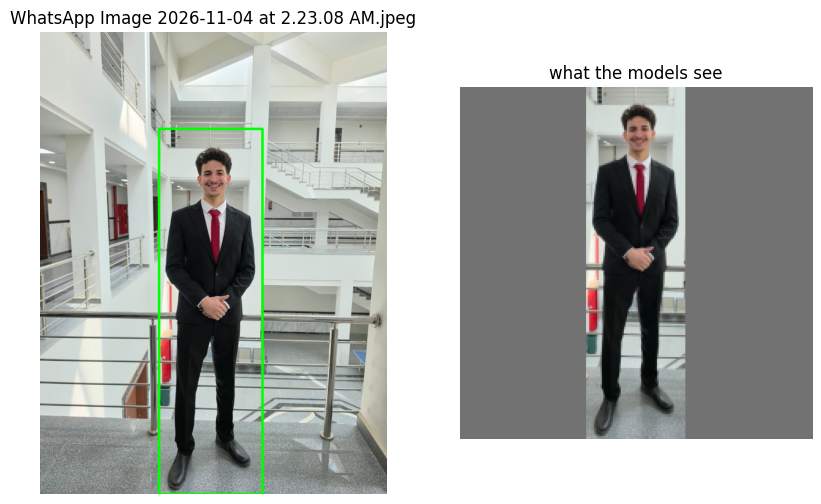

,classical,deep,estimate
age,old,old (75% sure),49 years
height,tall,tall (81% sure),182 cm
weight,normal (47% sure),overweight (76% sure),80 kg
gender,male,male (99% sure),


In [25]:
bundle = load(WORK_DIR / 'body_states_models.joblib')
backbone = load_backbone(bundle['config']['CNN_BACKBONE'])
detector = load_detector()

if IN_COLAB:
    from google.colab import files
    photos = {name: cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
              for name, data in files.upload().items()}
else:
    p = os.environ.get('BSD_TEST_IMAGE') or str(find_images(DATA_DIR)[0])
    photos = {Path(p).name: cv2.imread(p)}

for name, img in photos.items():
    if img is None:
        print(f'{name}: not an image OpenCV can read')
        continue
    person, box = crop_person(img, detector)
    shown = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    if box:
        cv2.rectangle(shown, box[:2], box[2:], (0, 255, 0), max(2, img.shape[1] // 150))
    fig, axes = plt.subplots(1, 2, figsize=(10, 6))
    axes[0].imshow(shown)
    axes[0].set_title(name if box else f'{name}\n(no person found, using the whole photo)')
    axes[1].imshow(cv2.cvtColor(letterbox(person, (CNN_SIZE, CNN_SIZE)), cv2.COLOR_BGR2RGB))
    axes[1].set_title('what the models see')
    for ax in axes:
        ax.axis('off')
    plt.show()
    display(predict_person(person, bundle, backbone))

## 14. Limitations and next steps

**Read the results with these in mind**
- **Height from one photo is mostly guesswork.** Without something of known size in the picture, a model can only use
  indirect cues such as gender and body proportions. Compare the height scores with the baseline before trusting them.
- **Weight/BMI is hidden by clothing, pose and camera angle.**
- **The labels are public celebrity data** and contain typos (section 2 shows some). Some will be wrong.
- **Celebrities aren't a typical population**, so the models are biased towards how celebrities look. This is a
  learning project: don't use it to make decisions about real people.

**Ideas for a v3**
- Fine-tune the CNN end to end, with one shared network and four output heads (multi-task learning).
- Add face-crop features for age and gender, which mostly show in the face.
- Try stronger pretrained backbones (`convnext_tiny` here, or CLIP / DINOv2).
- Data augmentation (flips, small crops, color jitter) when fine-tuning.